# Sistemas recomendadores

1. **Recomendador simple:** Top de películas usando la media ponderada de IMDB.
2. **Basado en contenido (sinopsis):** películas con trama similar usando TF-IDF + similitud coseno.
3. **Basado en contenido mejorado:** usando palabras clave y géneros (metadata soup) + CountVectorizer.

In [1]:
import os
from ast import literal_eval

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity

## Carga de datos

In [2]:
URL_BASE = 'https://raw.githubusercontent.com/mendiolaleonel2002-debug/sistema_recomendaciones/main/data/'

def cargar_csv(nombre):
    # Usa el archivo local si existe; si no (por ejemplo en Colab), lo lee de GitHub
    ruta = f'./data/{nombre}'
    if not os.path.exists(ruta):
        ruta = URL_BASE + nombre
    return pd.read_csv(ruta, low_memory=False)

df = cargar_csv('movies_metadata.csv')
print(df.shape)
df[['title', 'vote_count', 'vote_average', 'overview']].head(3)

(45466, 24)


,title,vote_count,vote_average,overview
0,Toy Story,5415.0,7.7,"Led by Woody, Andy's toys live happily in his ..."
1,Jumanji,2413.0,6.9,When siblings Judy and Peter discover an encha...
2,Grumpier Old Men,92.0,6.5,A family wedding reignites the ancient feud be...


# 1. Recomendador simple (Top IMDB)

Usamos la media ponderada de IMDB para no favorecer películas con pocos votos:

$$WR = \frac{v}{v+m} R + \frac{m}{v+m} C$$

- **v**: número de votos, **R**: calificación promedio
- **m**: votos mínimos (percentil 90), **C**: calificación media de todas las películas

In [3]:
C = df['vote_average'].mean()
m = df['vote_count'].quantile(0.90)

print(f'C (calificación media): {C:.2f}')
print(f'm (votos mínimos, percentil 90): {m}')

C (calificación media): 5.62
m (votos mínimos, percentil 90): 160.0


In [4]:
q_movies = df.copy().loc[df['vote_count'] >= m]
print('Películas que califican:', q_movies.shape[0], 'de', df.shape[0])

Películas que califican: 4555 de 45466


In [5]:
def weighted_rating(x, m=m, C=C):
    v = x['vote_count']
    R = x['vote_average']
    return (v / (v + m) * R) + (m / (m + v) * C)

q_movies['score'] = q_movies.apply(weighted_rating, axis=1)
q_movies = q_movies.sort_values('score', ascending=False)

q_movies[['title', 'vote_count', 'vote_average', 'score']].head(15)

,title,vote_count,vote_average,score
314,The Shawshank Redemption,8358.0,8.5,8.445869
834,The Godfather,6024.0,8.5,8.425439
10309,Dilwale Dulhania Le Jayenge,661.0,9.1,8.421453
12481,The Dark Knight,12269.0,8.3,8.265477
2843,Fight Club,9678.0,8.3,8.256385
292,Pulp Fiction,8670.0,8.3,8.251406
522,Schindler's List,4436.0,8.3,8.206639
23673,Whiplash,4376.0,8.3,8.205404
5481,Spirited Away,3968.0,8.3,8.196055
2211,Life Is Beautiful,3643.0,8.3,8.187171


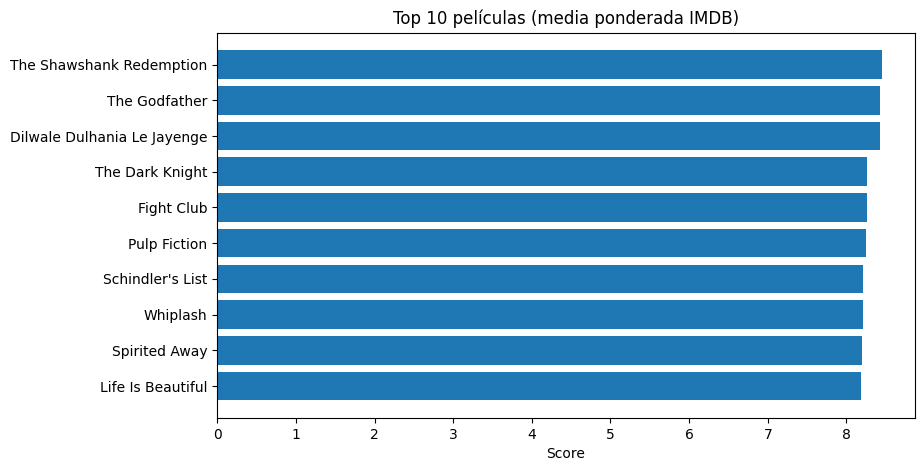

In [6]:
top10 = q_movies.head(10).iloc[::-1]

plt.figure(figsize=(9, 5))
plt.barh(top10['title'], top10['score'])
plt.title('Top 10 películas (media ponderada IMDB)')
plt.xlabel('Score')
plt.show()

# 2. Recomendador basado en contenido (sinopsis)

Convertimos la sinopsis (`overview`) de cada película en un vector TF-IDF y buscamos las películas más parecidas con similitud coseno.

In [7]:
df['overview'] = df['overview'].fillna('')

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['overview'])

print(tfidf_matrix.shape)
tfidf.get_feature_names_out()[5000:5010]

(45466, 75827)


array(['avails', 'avaks', 'avalanche', 'avalanches', 'avallone', 'avalon',
       'avant', 'avanthika', 'avanti', 'avaracious'], dtype=object)

La lección calcula la matriz de similitud completa (45,466 x 45,466). Eso ocupa unos **16 GB de RAM** y en Colab o en una laptop normal se traba.

Por eso calculamos la similitud **solo para la película que buscamos** contra todas las demás. El resultado es el mismo, pero usa muchísima menos memoria.

In [8]:
indices = pd.Series(df.index, index=df['title']).drop_duplicates()
indices = indices[~indices.index.duplicated(keep='first')]
indices[:10]

,0
title,
Toy Story,0
Jumanji,1
Grumpier Old Men,2
Waiting to Exhale,3
Father of the Bride Part II,4
Heat,5
Sabrina,6
Tom and Huck,7
Sudden Death,8


In [9]:
def get_recommendations(title, matrix, n=10):
    # 1. Índice de la película
    idx = indices[title]

    # 2. Similitud coseno de esa película contra todas
    #    (con TF-IDF o vectores normalizados, linear_kernel = similitud coseno)
    sim = cosine_similarity(matrix[idx], matrix).flatten()

    # 3. Ordenar de mayor a menor y quitar la propia película
    similares = sim.argsort()[::-1]
    similares = [i for i in similares if i != idx][:n]

    # 4. Regresar títulos y su similitud
    return pd.DataFrame({'title': df['title'].iloc[similares].values,
                         'similitud': sim[similares].round(3)})

In [10]:
get_recommendations('The Dark Knight Rises', tfidf_matrix)

,title,similitud
0,The Dark Knight,0.327
1,Batman Forever,0.316
2,Batman Returns,0.296
3,Batman: Under the Red Hood,0.288
4,Batman,0.271
5,Batman Unmasked: The Psychology of the Dark Kn...,0.253
6,Batman Beyond: Return of the Joker,0.234
7,Batman: Year One,0.204
8,"Batman: The Dark Knight Returns, Part 1",0.199
9,Batman: Mask of the Phantasm,0.189


In [11]:
get_recommendations('The Godfather', tfidf_matrix)

,title,similitud
0,The Godfather: Part II,0.476
1,The Godfather Trilogy: 1972-1990,0.356
2,The Godfather: Part III,0.183
3,Blood Ties,0.154
4,Household Saints,0.141
5,Start Liquidation,0.134
6,Election,0.132
7,A Mother Should Be Loved,0.130
8,Short Sharp Shock,0.130
9,Beck 28 - Familjen,0.128


Con la sinopsis recomienda casi puras películas de Batman. Alguien a quien le gustó *The Dark Knight Rises* probablemente también disfrute otras películas del mismo estilo o director, y eso no lo captura la sinopsis.

# 3. Recomendador mejorado (metadata soup)

El curso solo proporciona `movies_metadata.csv` y `keywords.csv` (no `credits.csv`, que trae actores y director). Por eso construimos la *soup* con **palabras clave y géneros**.

In [12]:
keywords = cargar_csv('keywords.csv')

# Quitar ids mal formateados y convertir a enteros
df['id'] = pd.to_numeric(df['id'], errors='coerce')
df = df.dropna(subset=['id'])
df['id'] = df['id'].astype(int)
keywords['id'] = keywords['id'].astype(int)

df = df.merge(keywords, on='id')
df = df.drop_duplicates(subset='id').reset_index(drop=True)
print(df.shape)

(45432, 25)


In [13]:
for feature in ['keywords', 'genres']:
    df[feature] = df[feature].fillna('[]').apply(literal_eval)

def get_list(x, n=None):
    if isinstance(x, list):
        names = [i['name'] for i in x]
        return names[:n] if n else names
    return []

def clean_data(x):
    # minúsculas y sin espacios: 'science fiction' -> 'sciencefiction'
    return [str.lower(i.replace(' ', '')) for i in x]

df['keywords'] = df['keywords'].apply(lambda x: clean_data(get_list(x, 5)))
df['genres'] = df['genres'].apply(lambda x: clean_data(get_list(x, 3)))

df[['title', 'keywords', 'genres']].head(3)

,title,keywords,genres
0,Toy Story,"[jealousy, toy, boy, friendship, friends]","[animation, comedy, family]"
1,Jumanji,"[boardgame, disappearance, basedonchildren'sbo...","[adventure, fantasy, family]"
2,Grumpier Old Men,"[fishing, bestfriend, duringcreditsstinger, ol...","[romance, comedy]"


In [14]:
def create_soup(x):
    # Repetimos los géneros 2 veces para darles un poco más de peso
    return ' '.join(x['keywords']) + ' ' + ' '.join(x['genres'] * 2)

df['soup'] = df.apply(create_soup, axis=1)
df[['title', 'soup']].head(3)

,title,soup
0,Toy Story,jealousy toy boy friendship friends animation ...
1,Jumanji,boardgame disappearance basedonchildren'sbook ...
2,Grumpier Old Men,fishing bestfriend duringcreditsstinger oldmen...


Usamos **CountVectorizer** en lugar de TF-IDF porque no queremos bajarle el peso a un género o palabra clave solo porque aparece en muchas películas.

In [15]:
count = CountVectorizer(stop_words='english')
count_matrix = count.fit_transform(df['soup'])
print(count_matrix.shape)

indices = pd.Series(df.index, index=df['title'])
indices = indices[~indices.index.duplicated(keep='first')]

(45432, 13162)


In [16]:
get_recommendations('The Dark Knight Rises', count_matrix)

,title,similitud
0,Batman Begins,0.882
1,The Dark Knight,0.882
2,Baseline,0.840
3,Lure: Teen Fight Club,0.840
4,Jiang Hu,0.840
5,iNumber Number,0.840
6,Apaharan,0.840
7,Citizen,0.840
8,Two Rabbits,0.840
9,Titli,0.840


In [17]:
get_recommendations('The Godfather', count_matrix)

,title,similitud
0,In the Name of the Law,0.832
1,The Devil Strikes at Night,0.784
2,Feast of July,0.784
3,Ghosts... of the Civil Dead,0.784
4,Teen-Age Crime Wave,0.784
5,Le 7ème juré,0.784
6,Tracks,0.784
7,Aprel,0.784
8,Allotment Wives,0.784
9,Nice Guy,0.784


# 4. Extra: filtro de popularidad

Sugerencia de la lección: tomar las 30 más similares y ordenarlas por la media ponderada de IMDB, para no recomendar películas muy parecidas pero malas o desconocidas.

In [18]:
def get_recommendations_populares(title, matrix, n=10):
    candidatas = get_recommendations(title, matrix, n=30)
    candidatas = candidatas.merge(df[['title', 'vote_count', 'vote_average']].drop_duplicates('title'), on='title')

    candidatas = candidatas[candidatas['vote_count'] >= candidatas['vote_count'].quantile(0.5)].copy()
    candidatas['score'] = candidatas.apply(weighted_rating, axis=1)

    return candidatas.sort_values('score', ascending=False).head(n)[['title', 'similitud', 'vote_count', 'score']]

get_recommendations_populares('The Dark Knight Rises', count_matrix)

,title,similitud,vote_count,score
1,The Dark Knight,0.882,12269.0,8.265477
0,Batman Begins,0.882,7511.0,7.460750
13,Faster,0.840,577.0,5.995405
8,Two Rabbits,0.840,39.0,5.908609
18,Fear Over the City,0.840,24.0,5.772354
16,Shaitan,0.840,17.0,5.722108
14,Police Story 2013,0.840,92.0,5.684576
20,Pitbull Tough Women,0.840,16.0,5.680188
11,Awarapan,0.840,10.0,5.658313
29,Island of Fire,0.840,26.0,5.657598


# Conclusiones
- El **recomendador simple** es fácil de hacer y da un buen Top general, pero recomienda lo mismo a todos.
- El **basado en sinopsis** encuentra películas con tramas parecidas, aunque se queda en lo literal (puro Batman).
- El **basado en metadata** (palabras clave y géneros) da recomendaciones más variadas. Con `credits.csv` (actores y director) mejoraría todavía más.
- Agregar el **filtro de popularidad** ayuda a que las recomendaciones, además de parecidas, sean películas bien calificadas.
- Calcular la similitud solo para la película buscada evita usar ~16 GB de RAM.